# Portfolio Diversification Challenge — Beat the Market!

## Your role

You are a team of financial advisers working for a wealth-management firm.

Your client wants a portfolio with **low risk and a limited number of stocks**. Adding more stocks can improve diversification, but it also makes the portfolio more complex to manage.

Your challenge is to design the most efficient portfolio possible, balancing **portfolio volatility and the number of stocks**.

You will compete against other teams in a **90-minute live competition**.

**Can your team build the best portfolio in the class?**

## 1. Dataset

Use the historical stock prices provided in the following file:

**[Download S&P 500 Stock Prices — SP500_comp_data.xlsx](https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_2_Carteras_Intro/data/SP500_comp_data.xlsx)**

The original dataset contains **504 stocks and 8,475 dates**.

### Data preparation

All teams must work with the same cleaned dataset:

- Exclude stocks with **more than 20% missing or invalid price observations**. Non-numeric, zero and negative prices are considered invalid.
- After removing these stocks, eliminate all dates containing missing or invalid prices among the remaining stocks.
- Do not fill or interpolate missing observations.
- Calculate daily **log returns** from the cleaned prices.
- All portfolios must be evaluated using exactly the **same return dates**.

The instructor will use the official cleaned dataset to evaluate every submission.

## 2. Portfolio construction rules

Your portfolio must satisfy the following conditions:

- Select between **5 and 30 different stocks** from the eligible universe.
- Assign **equal weights** to all selected stocks: each stock must have weight `1/K`, where `K` is the number of stocks.
- Calculate the portfolio's daily returns.
- Calculate annualized sample volatility using:

  `Annualized Volatility = portfolio_returns.std(ddof=1) * np.sqrt(252)`

You may develop and implement **any stock-selection method you choose**.

## 3. How the competition works

Each team will work independently to find the best possible portfolio.

The instructor will evaluate submitted portfolios using a **fixed competition Score** that considers:

- **Portfolio risk:** lower volatility is better.
- **Portfolio complexity:** holding fewer stocks is preferable.

The exact scoring formula will remain confidential during the competition and will be revealed at the end.

There is **no predetermined volatility target**. Your goal is to find a portfolio that achieves the best possible balance between risk and the number of stocks.

### Submitting a portfolio

When your team believes it has found a competitive portfolio:

1. Give the instructor your **team name**.
2. Submit the **selected stock tickers in alphabetical order**, separated by commas.
3. The instructor will check the portfolio, calculate its volatility and Score using the official dataset, and update the live leaderboard.

**Example submission:**

`Team Alpha: AAPL,AMZN,JNJ,KO,MSFT`

You do not need to calculate the official Score yourself.

## 4. Maximum number of attempts

Each team has a maximum of **4 official submissions** during the 90-minute competition.

- You may run as many calculations and simulations as you want on your own computer.
- Only portfolios submitted to the instructor count as official attempts.
- Each new, different portfolio submitted uses one attempt.
- Duplicate portfolios are not accepted as new submissions.
- If a new submission performs worse than your previous best, **your best result is retained**.
- Once your team has used all four attempts, you cannot submit another portfolio.

**Choose carefully when to submit. A good strategy is not only about finding better portfolios, but also about deciding when your results are competitive enough to enter the leaderboard.**


## 5. Live Leaderboard

The instructor will update the leaderboard whenever teams submit new portfolios.

During the competition, you will see your team's ranking, how close you are to the leader, and how many attempts you have remaining.

### Example Leaderboard

| Rank | Team | Performance | Attempts | Change |
|:---:|:---|---:|:---:|:---:|
| 🥇 1 | Team Alpha | 100.00 | 2/4 | — |
| 🥈 2 | Team Delta | 99.72 | 1/4 | ↑ 2 |
| 🥉 3 | Team Beta | 98.85 | 3/4 | ↓ 1 |
| 4 | Team Gamma | 97.34 | 2/4 | ↓ 1 |
| 5 | Team Omega | 95.61 | 1/4 | — |

*Illustrative results only.*

### Understanding the Leaderboard

- **Rank:** Your team's current position.
- **Performance:** The leading team always scores 100. Other teams receive a lower value indicating how close they are to the leader.
- **Attempts:** Number of official submissions used out of the maximum of four.
- **Change:** Movement in the ranking since the previous update (↑ up, ↓ down).

The Performance Index is a relative competition measure, **not an academic grade**.

To maintain the competitive challenge, the number of stocks, portfolio volatility, and exact scoring formula will remain confidential during the competition.

**Only your team's best submission counts.** You can continue improving your portfolio until you have used all four attempts or the 90-minute competition ends.

At the end, the instructor will reveal the final portfolio statistics, the scoring formula, and the winning teams.


## 6. How to win

The winner will be the team with the **best official Score** at the end of the competition.

Remember:

- A portfolio with fewer stocks is not necessarily better.
- A portfolio with lower volatility is not necessarily better if it requires substantially more stocks.
- Improving your selection of stocks can be more valuable than simply increasing the number of stocks.

**Every submission is an opportunity to improve your position, but you only have four attempts.**

## 7. Final discussion

At the end of the competition, the instructor will reveal the scoring formula and the final results.

Each team should be prepared to briefly explain:

1. How did you select the stocks?
2. How did you try to improve your portfolio?
3. What was the most important factor in reducing portfolio risk?
4. Would you change your strategy if you could start again?

## Financial interpretation

This competition illustrates a fundamental investment-management problem: **how to achieve effective diversification without holding an unnecessarily large number of stocks**.

The best portfolio is not necessarily the one with the lowest volatility or the fewest assets considered separately. It is the one that offers the best balance between these objectives under the competition's scoring rules.

The results are based on historical data and do not guarantee future investment performance.

**Good luck — and may the best portfolio win!**

---
# Instructor solution — Two simple greedy strategies

We will solve the challenge with two methods:

- **Greedy Forward:** build a portfolio by adding one stock at a time.
- **Greedy Backward:** start with all eligible stocks and remove one stock at a time.

Both methods search for low-volatility **equal-weight** portfolios. We then compare portfolio risk **and** the number of stocks, as required by the challenge. These are historical, in-sample solutions; greedy choices do not guarantee the global optimum.

The official scoring formula below is for the **instructor's solution**, to be revealed only after the competition. It was not part of the student instructions.

## 1. Load and clean the prices

Use the **same dataset and cleaning rules** as the challenge: treat invalid prices as missing; exclude stocks with more than 20% missing or invalid prices; remove incomplete dates; calculate daily log returns. No interpolation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_URL = (
    "https://raw.githubusercontent.com/alfonso-santos/"
    "microcredencial-carteras-python/Finance_Technology/"
    "Tema_2_Carteras_Intro/data/SP500_comp_data.xlsx"
)
MIN_K, MAX_K = 5, 30
TRADING_DAYS = 252

# Read stock prices directly from the course repository.
prices = pd.read_excel(DATA_URL, index_col="Date")
prices.index = pd.to_datetime(prices.index)
prices = prices.sort_index().apply(pd.to_numeric, errors="coerce")

# Prices of zero or less are invalid.
prices = prices.where(prices > 0)

# Remove stocks with over 20% invalid/missing prices, then incomplete dates.
prices = prices.loc[:, prices.isna().mean() <= 0.20].dropna()

# Daily log returns, computed on the same dates for every portfolio.
returns = np.log(prices / prices.shift(1)).dropna()

print("Eligible stocks:", returns.shape[1])
print("Return observations:", len(returns))
print("Sample:", returns.index.min().date(), "to", returns.index.max().date())

Eligible stocks: 325
Return observations: 6832
Sample: 1996-07-01 to 2023-08-22


## 2. One risk measure for every portfolio

All stocks receive equal weights ($1/K$). Portfolio risk depends on the variances of the selected stocks **and their covariances**. The function below calculates the annualized sample volatility, equivalent to `portfolio_returns.std(ddof=1) * np.sqrt(252)`.

In [8]:
tickers = returns.columns.to_list()
cov = returns.cov()  # Sample covariance (ddof=1)


def portfolio_volatility(selected, cov, trading_days=252):
    """Calculate the annualized volatility of an equally weighted portfolio."""

    # Select the covariance matrix of the chosen stocks
    portfolio_cov = cov.iloc[selected, selected]

    # Calculate portfolio variance (equal weights)
    variance = portfolio_cov.to_numpy().mean()

    # Annualize volatility
    return np.sqrt(variance * trading_days)


# Simple example with five stocks.
print(f"Example annualized volatility: {portfolio_volatility(list(range(5)), cov):.2%}",)

Example annualized volatility: 22.05%


## 3. Greedy Forward — Add one stock at a time

Start with the **least volatile stock**. Next, add the stock that gives the lowest volatility for the new equally weighted portfolio. Continue until the portfolio contains 30 stocks, saving each portfolio from 5 to 30 stocks.

**Financial interpretation:** each addition is judged by how well the candidate stock works *with the stocks already selected*, not by its individual volatility alone.

In [10]:
# Start with the least volatile individual stock.
selected = [int(np.argmin(np.diag(cov)))]
forward = {}

while len(selected) < MAX_K:
    # Choose the stock that minimizes volatility after it is added.
    remaining = [i for i in range(len(tickers)) if i not in selected]
    best_stock = min(remaining, key=lambda i: portfolio_volatility(selected + [i], cov))
    selected.append(best_stock)

    if len(selected) >= MIN_K:
        forward[len(selected)] = selected.copy()

print(f"Forward, 20 stocks: {portfolio_volatility(forward[20], cov):.2%}")

Forward, 20 stocks: 13.31%


## 4. Greedy Backward — Remove one stock at a time

Start with **all eligible stocks**. At each step, remove the stock that leaves the lowest-volatility equally weighted portfolio. Save the portfolios containing 30, 29, ..., 5 stocks.

**Financial interpretation:** the asset we remove is the one whose removal leaves the best-diversified portfolio *at that step*. For speed, we use the covariance matrix to compare every possible removal in one calculation.

In [14]:
selected = list(range(len(tickers)))
backward = {}

while len(selected) >= MIN_K:
    if len(selected) <= MAX_K:
        backward[len(selected)] = selected.copy()
    if len(selected) == MIN_K:
        break

    # Current covariance matrix.
    block = cov.iloc[selected, selected]
    k = len(selected)

    # Portfolio variance after removing each stock, one at a time.
    variances_after_removal = (
        block.to_numpy().sum()
        - 2 * block.to_numpy().sum(axis=1)
        + np.diag(block)
    ) / (k - 1) ** 2

    # Remove the stock that leaves the lowest variance.
    selected.pop(int(np.argmin(variances_after_removal)))

print(f"Backward, 20 stocks: {portfolio_volatility(backward[20], cov):.2%}")

Backward, 20 stocks: 13.28%


## 5. Compare volatility and portfolio size

The challenge has **no fixed volatility target**. We must consider the trade-off: holding more stocks may lower risk, but it also makes the portfolio more complex. First, compare the two methods for every portfolio size.

,Forward volatility (%),Backward volatility (%)
Stocks,,
5,14.454,14.454
6,14.310,14.313
7,14.160,14.161
8,14.043,14.032
9,13.943,13.923
10,13.811,13.786
11,13.710,13.663
12,13.626,13.550
13,13.561,13.489


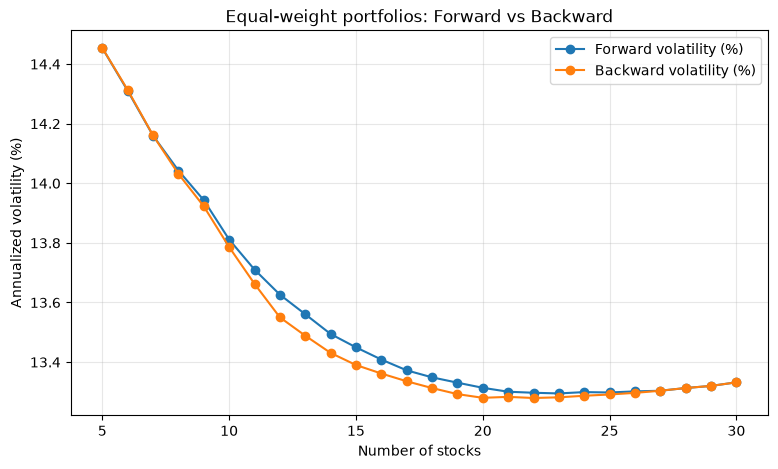

In [15]:
rows = []
for k in range(MIN_K, MAX_K + 1):
    rows.append({
        "Stocks": k,
        "Forward volatility (%)": 100 * portfolio_volatility(forward[k],cov),
        "Backward volatility (%)": 100 * portfolio_volatility(backward[k],cov),
    })

comparison = pd.DataFrame(rows).set_index("Stocks")
display(comparison.round(3))

comparison.plot(figsize=(9, 5), marker="o")
plt.xlabel("Number of stocks")
plt.ylabel("Annualized volatility (%)")
plt.title("Equal-weight portfolios: Forward vs Backward")
plt.grid(alpha=0.3)
plt.show()

## 6. Instructor evaluation — Select the best portfolio

During the competition the scoring formula was **confidential**. The instructor's official formula combines volatility and the number of stocks:

`Score = 100 × annualized volatility + 0.05 × (K − 5)`

Here volatility is a **decimal** (e.g., 0.15 for 15%). **Lower Score is better.** We calculate it for every size and both methods, and identify the best candidate. This is the official evaluation rule, **not a volatility threshold**.

In [20]:
PENALTY = 0.05  # Additional score points per stock beyond five.


def portfolio_score(selected):
    k = len(selected)
    return 100 * portfolio_volatility(selected, cov) + PENALTY * (k - MIN_K)


results = []
for method, portfolios in [("Forward", forward), ("Backward", backward)]:
    for k, stocks in portfolios.items():
        results.append({
            "Method": method,
            "Stocks": k,
            "Volatility (%)": 100 * portfolio_volatility(stocks, cov),
            "Score": portfolio_score(stocks),
            "Selected indices": stocks,
        })

results = pd.DataFrame(results).sort_values(
    ["Score", "Volatility (%)", "Stocks", "Method"]
).reset_index(drop=True)

# Show the best portfolios, without the technical column of stock indices.
display(results.drop(columns="Selected indices").head(10).round(4))

winner = results.iloc[0]
winning_tickers = sorted(tickers[i] for i in winner["Selected indices"])
print(f"Best method: {winner['Method']}")
print(f"Stocks: {winner['Stocks']}")
print(f"Annualized volatility: {winner['Volatility (%)']:.4f}%")
print(f"Official score: {winner['Score']:.4f}")
print("Tickers: " + ",".join(winning_tickers))

,Method,Stocks,Volatility (%),Score
0,Backward,14,13.4309,13.8809
1,Backward,13,13.4887,13.8887
2,Backward,15,13.3902,13.8902
3,Backward,12,13.5502,13.9002
4,Backward,16,13.3617,13.9117
5,Backward,17,13.3357,13.9357
6,Forward,14,13.4943,13.9443
7,Forward,15,13.4496,13.9496
8,Forward,16,13.4086,13.9586
9,Forward,13,13.5607,13.9607


Best method: Backward
Stocks: 14
Annualized volatility: 13.4309%
Official score: 13.8809
Tickers: ACGL,AJG,CAG,CLX,ED,GIS,HRL,JNJ,MCD,NEM,SJM,SO,WMT,WST


## 7. Display a specific portfolio for submission

You can choose either method and any portfolio size between 5 and 30. Tickers are sorted alphabetically, as requested in the original challenge. The selected portfolio can then be compared with the official winner above.

In [23]:
METHOD = "Backward"  # Or "Forward"
K = 20                # Any number from 5 to 30

portfolios = {"Forward": forward, "Backward": backward}[METHOD]
selected = portfolios[K]
chosen_tickers = sorted(tickers[i] for i in selected)

print(f"Method: {METHOD}")
print(f"Number of stocks: {K}")
print(f"Annualized volatility: {portfolio_volatility(selected, cov):.4%}")
print(f"Score (revealed after the competition): {portfolio_score(selected):.4f}")
print("Tickers: " + ",".join(chosen_tickers))

Method: Backward
Number of stocks: 20
Annualized volatility: 13.2802%
Score (revealed after the competition): 14.0302
Tickers: ACGL,AJG,BDX,CAG,CHD,CLX,ED,GIS,HRL,JNJ,KR,LMT,MCD,NEM,SJM,SO,VZ,WEC,WMT,WST


## Discussion

1. At the same number of stocks, which method gives a lower volatility?
2. Why might the lowest-volatility portfolio **not** obtain the best competition Score?
3. Why can an individually volatile stock still help diversify a portfolio?
4. Why do Forward and Backward choose different sets of stocks?

**Key lesson:** Portfolio selection is about **covariances and diversification**, not just picking individually safe stocks. Adding stocks may improve diversification, but the competition also rewards simpler portfolios. Neither greedy method guarantees the globally best combination.